# Project 1: Experiments (Task 5, and Task 6 if done)

This notebook is a skeleton. Keep its sections and fill them in.

- All agents are defined in `agents.py`. Import them from there; do not define agents in this notebook.
- Run every season with `play(agent, bay)` from `agents.py`.
- Document each step: what you run, why, and what you observe.
- The notebook must run from top to bottom without errors (Kernel, Restart and Run All).

In [6]:
import numpy as np
import matplotlib.pyplot as plt

from fishing import FishingBay, ContextualBay, load_log, choices, SPOTS
from agents import play, RandomAgent, RandomContextualAgent  # add your own agents here
# Our agents, all defined in agents.py (none is defined in this notebook):
#   the two human rules of Part II, the three methods of the book, and the Part IV agents.
from agents import (HumanRuleAgent, ThresholdRuleAgent,
                    EpsilonGreedyAgent, OptimisticGreedyAgent, UCBAgent,
                    ContextualWrapper, LinearRegressionAgent, LinUCBAgent, KNNAgent)

### Settings and helper functions (no agents here, only measurement code)

**Seeds.** Evaluation uses bays with seeds `0 ... 999` (1000 bays per season). The default parameters
of the agents in `agents.py` were tuned on *other* seeds (10000 and above), so the results below are
not measured on the bays used for tuning.

**Performance measures (our Task 3 measure).** The total catch mixes two things: how good the bay is
(luck of the draw of the 5 averages) and how noisy the daily catches were (luck of the day). We report:

- `total`: total catch (kg), what the game shows.
- `efficiency = total / best_possible`: removes the luck of the bay (a bay where every spot is poor
  gives a small total whatever you do).
- `decision score = sum of the TRUE average of the spot chosen each day / best_possible`: also removes
  the day-to-day noise of the catches. It only depends on the decisions, so it is our measure that separates
  decisions from luck. It uses `bay.reveal()`, which is only read **after** the season (allowed by the rules).

In [7]:
N_BAYS = 1000
SEEDS = range(N_BAYS)              # evaluation bays (tuning used seeds >= 10000)
SEASONS = (1, 2, 3)

def true_mean_of_day(bay, day, spot):
    """True average of `spot` on day `day` (1-based), read after the season with reveal()."""
    r = bay.reveal()
    if "change_day" in r and day >= r["change_day"]:
        return r["means_after_change"][spot]
    return r["means"][spot]

def decision_score(bay, spots):
    """Sum of the true averages of the chosen spots, divided by best_possible (1 = perfect decisions)."""
    expected = sum(true_mean_of_day(bay, d + 1, s) for d, s in enumerate(spots))
    return expected / bay.best_possible()

# Build each bay once and reuse it: play() resets the bay, so every agent sees exactly the same bays.
BAYS = {s: [FishingBay(season=s, seed=seed) for seed in SEEDS] for s in SEASONS}

def evaluate(make_agent, season, bays=None):
    """Play make_agent(seed) on every bay of a season. Returns arrays total, efficiency, decision score."""
    bays = BAYS[season] if bays is None else bays
    tot, eff, dec = [], [], []
    for bay in bays:
        total = play(make_agent(bay.seed), bay)   # agent seed = bay seed: reproducible
        tot.append(total)
        eff.append(total / bay.best_possible())
        dec.append(decision_score(bay, [s for s, _ in bay.history]))
    return np.array(tot), np.array(eff), np.array(dec)

## 0. Your team logs

Put the JSON log of each team member next to this notebook and list the files below.

In [8]:
# Our logs are in the logs/ folder next to this notebook.
TEAM_LOG_FILES = [
    "fishing_log_bouazza.json",
    "fishing_log_kanakara.json",
    "fishing_log_kumarsh.json",
]
logs = [load_log(path) for path in TEAM_LOG_FILES]
NAMES = [log["student_id"] for log in logs]

# Our team's results on their own bays, with the three measures defined above
print(f"{'member':10s} {'season':>6s} {'total':>7s} {'best':>7s} {'efficiency':>10s} {'decision':>9s}")
HUMAN = {}   # (name, season) -> (total, efficiency, decision score)
for name, log in zip(NAMES, logs):
    for s in SEASONS:
        spots, catches = choices(log, season=s)
        bay = FishingBay.from_log(log, season=s)
        total = round(sum(catches), 1)
        HUMAN[name, s] = (total, total / bay.best_possible(), decision_score(bay, spots))
        print(f"{name:10s} {s:6d} {total:7.1f} {bay.best_possible():7.1f} "
              f"{HUMAN[name, s][1]:10.3f} {HUMAN[name, s][2]:9.3f}")

member     season   total    best efficiency  decision
bouazza         1   176.3   213.0      0.828     0.818
bouazza         2    71.2    99.0      0.719     0.711
bouazza         3   216.7   279.0      0.777     0.753
kanakara        1   198.6   288.0      0.690     0.771
kanakara        2    45.5    64.0      0.711     0.769
kanakara        3   139.5   259.5      0.538     0.534
kumarsh         1   232.9   297.0      0.784     0.837
kumarsh         2    54.5    77.0      0.708     0.599
kumarsh         3   156.9   226.5      0.693     0.732


**Observation.** Totals mislead. Kanakara's 198.6 kg came from a rich bay (288 kg possible), bouazza's
176.3 kg from a poor one (213 kg): their decisions are much closer than the totals say. In Season 3 only
bouazza kept a good score (0.753).

---
# Task 3. A performance measure that separates decisions from luck

| Part of Task 3 | Where it is |
|---|---|
| (a) the measure | cell *"Settings and helper functions"* (`decision_score`) |
| (b) proof that it separates decisions from luck | **section 1.3** (it needs the agents of section 1.2) |
| (c) our team across the three seasons | **here**: 3.1 the shorter Season 2, 3.2 the change in Season 3 |

**The measure.** For a season where we chose the spots $A_1,\dots,A_T$,

$$\text{decision score}=\frac{\sum_{t} q_t(A_t)}{\texttt{best\_possible}},$$

with $q_t(A_t)$ the **true mean** of the spot chosen on day $t$ (read with `bay.reveal()` only after the season).
It is 1 if we fish the best spot every day. The true means remove the luck of the day, `best_possible` removes
the luck of the bay. Day by day we call the same ratio the **choice quality** (1 = best spot of that day).

member     season  days  all 5 spots tried on day  decision score
bouazza         1    30                        11           0.818
bouazza         2    10                         7           0.711
bouazza         3    30                         7           0.753
kanakara        1    30                         9           0.771
kanakara        2    10                         5           0.769
kanakara        3    30                         5           0.534
kumarsh         1    30                        11           0.837
kumarsh         2    10                         5           0.599
kumarsh         3    30                         5           0.732


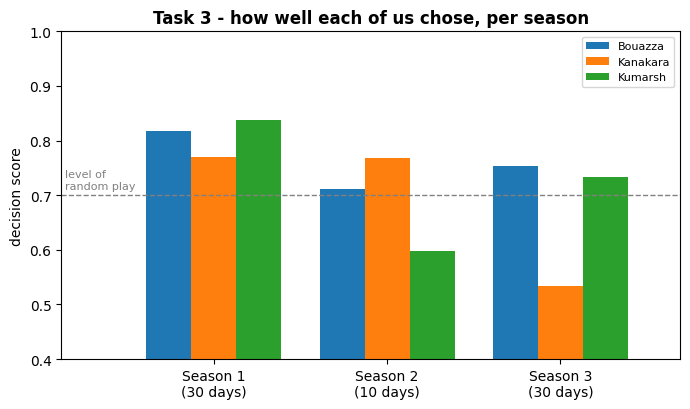

In [9]:
# =============================================================================
# Task 3.1 - the effect of the shorter Season 2
# =============================================================================
# We print, for each member and season, the day on which they had tried all five
# spots (the cost of exploring) and their decision score, then plot the scores.

def quality_per_day(bay, spots):
    """Choice quality of each day: true mean of the chosen spot / best true mean that day."""
    out = []
    for d, s in enumerate(spots):
        means = [true_mean_of_day(bay, d + 1, k) for k in range(len(SPOTS))]
        out.append(means[s] / max(means))
    return np.array(out)

print(f"{'member':10s} {'season':>6s} {'days':>5s} {'all 5 spots tried on day':>25s} {'decision score':>15s}")
DEC = {}
for name, log in zip(NAMES, logs):
    for s in SEASONS:
        spots, _ = choices(log, season=s)
        bay = FishingBay.from_log(log, season=s)
        d5 = next(d + 1 for d in range(len(spots)) if len(set(spots[: d + 1])) == len(SPOTS))
        DEC[name, s] = decision_score(bay, spots)
        print(f"{name:10s} {s:6d} {bay.days:5d} {d5:25d} {DEC[name, s]:15.3f}")

# --- figure: decision score of each member, per season ---
fig, ax = plt.subplots(figsize=(7, 4.2))
w, x = 0.26, np.arange(3)
for i, name in enumerate(NAMES):
    ax.bar(x + i * w, [DEC[name, s] for s in SEASONS], w, label=name.capitalize())
ax.axhline(0.70, ls="--", c="grey", lw=1)
ax.set_xlim(-0.62, 2.95)                      # room on the left for the baseline label
ax.text(-0.60, 0.712, "level of\nrandom play", fontsize=8, c="grey")
ax.set_xticks(x + w, [f"Season {s}\n({BAYS[s][0].days} days)" for s in SEASONS])
ax.set_ylim(0.4, 1.0); ax.set_ylabel("decision score"); ax.legend(fontsize=8)
ax.set_title("Task 3 - how well each of us chose, per season", fontweight="bold")
plt.tight_layout(); plt.show()

**Observation (Season 2).** Ten days are too few to explore. Kumarsh used 5 of his 10 days to try all five
spots and fell to **0.599**, below random play; bouazza used 7 days and fell to 0.711. Kanakara only rotates,
so the shorter season cost him nothing (0.769). The amount of exploration has to fit the length of the season -
section 4 shows the same thing for the agents.

member      favourite before  its mean before/after  new best  quality d1-15  quality d16-30  1st day on new best  days on it  settled from
bouazza      Lighthouse Reef        9.6 ->   2.3 Deep Channel           0.85            0.65                   21        4/15        day 28
kanakara         Rocky Point        2.3 ->   4.6  Old Pier           0.46            0.62                   16        3/15         never
kumarsh          Rocky Point        7.3 ->   6.6 Rocky Point           0.73            0.74                   17        3/15         never


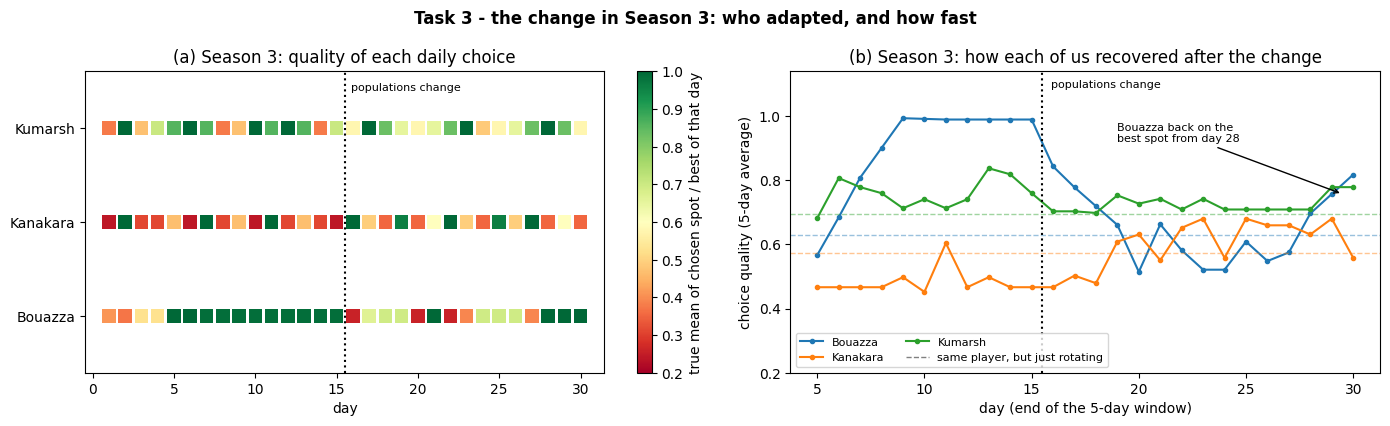

In [10]:
# =============================================================================
# Task 3.2 - the change in Season 3: what it is, who adapted, and how fast
# =============================================================================
# What the change is: on day 16 the simulator replaces the mean catch of every
# spot by a new value, so the spot that was the best before is usually not the
# best afterwards. Nothing is announced: the only signal is a drop in the catches.
#
# How we measure adaptation. "First day back on the new best spot" is not enough:
# a player who rotates visits every spot, so he reaches the new best spot by
# accident without having understood anything. We therefore look at the choice
# quality over a 5-day window, and at whether a player STAYS on the new best spot
# (a final run of at least 3 days).

W = 5                                   # window of the moving average, in days
print(f"{'member':10s} {'favourite before':>17s} {'its mean before/after':>22s} {'new best':>9s} "
      f"{'quality d1-15':>14s} {'quality d16-30':>15s} {'1st day on new best':>20s} "
      f"{'days on it':>11s} {'settled from':>13s}")
ADAPT = {}
for name, log in zip(NAMES, logs):
    bay = FishingBay.from_log(log, season=3)
    spots, _ = choices(log, season=3)
    r = bay.reveal()
    cd = r["change_day"]                             # 16
    q = quality_per_day(bay, spots)
    new_best = int(np.argmax(r["means_after_change"]))
    fav = int(np.bincount(spots[: cd - 1], minlength=len(SPOTS)).argmax())   # most fished before the change
    post = spots[cd - 1:]
    first = next((cd + i for i, a in enumerate(post) if a == new_best), None)
    run = 0                                          # length of the final run on the new best spot
    for a in reversed(post):
        if a == new_best:
            run += 1
        else:
            break
    settled = len(spots) - run + 1 if run >= 3 else None
    ADAPT[name] = (q, cd, settled)
    print(f"{name:10s} {SPOTS[fav]:>17s} {r['means'][fav]:10.1f} ->{r['means_after_change'][fav]:6.1f} "
          f"{SPOTS[new_best]:>9s} {q[:cd-1].mean():14.2f} {q[cd-1:].mean():15.2f} "
          f"{str(first):>20s} {f'{sum(a == new_best for a in post)}/{len(post)}':>11s} "
          f"{(f'day {settled}' if settled else 'never'):>13s}")

# --- figure ---
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3), gridspec_kw={"width_ratios": [1.1, 1]})
for i, name in enumerate(NAMES):
    q, cd, settled = ADAPT[name]
    # (a) one coloured square per day: how good was the spot chosen that day
    sc = axes[0].scatter(range(1, len(q) + 1), [i] * len(q), c=q, cmap="RdYlGn",
                         vmin=0.2, vmax=1, s=95, marker="s", edgecolors="none")
    # (b) 5-day moving average of the same quantity, with the player's own "rotating" baseline
    roll = np.convolve(q, np.ones(W) / W, mode="valid")
    line, = axes[1].plot(range(W, len(q) + 1), roll, marker="o", ms=3, label=name.capitalize())
    bay = FishingBay.from_log(log=logs[i], season=3)
    rotating = np.mean([np.mean([true_mean_of_day(bay, d + 1, k) for k in range(len(SPOTS))])
                        / max(true_mean_of_day(bay, d + 1, k) for k in range(len(SPOTS)))
                        for d in range(len(q))])
    axes[1].axhline(rotating, ls="--", lw=1, c=line.get_color(), alpha=0.45)
    if settled:
        axes[1].annotate(f"{name.capitalize()} back on the\nbest spot from day {settled}",
                         xy=(settled + 1.5, roll[settled + 1 - W]), xytext=(19.0, 0.92),
                         fontsize=8, arrowprops=dict(arrowstyle="->", lw=1))
plt.colorbar(sc, ax=axes[0], label="true mean of chosen spot / best of that day")
axes[0].axvline(15.5, ls=":", c="k"); axes[0].text(15.9, 2.40, "populations change", fontsize=8)
axes[0].set_yticks(range(3), [n.capitalize() for n in NAMES])
axes[0].set_xlabel("day"); axes[0].set_ylim(-0.6, 2.6)
axes[0].set_title("(a) Season 3: quality of each daily choice")
axes[1].axvline(15.5, ls=":", c="k"); axes[1].text(15.9, 1.09, "populations change", fontsize=8)
axes[1].plot([], [], ls="--", c="grey", lw=1, label="same player, but just rotating")
axes[1].set_xlabel("day (end of the 5-day window)"); axes[1].set_ylabel("choice quality (5-day average)")
axes[1].set_ylim(0.2, 1.14); axes[1].legend(fontsize=8, loc="lower left", ncol=2)
axes[1].set_title("(b) Season 3: how each of us recovered after the change")
fig.suptitle("Task 3 - the change in Season 3: who adapted, and how fast", fontweight="bold")
plt.tight_layout(); plt.show()

**Observation (Season 3).** The change: on day 16 every spot gets a new mean, with no warning.

- **Bouazza** was the only one exploiting (quality 1.00 before day 16). His spot fell from 9.6 to 2.3 kg and his
  quality to 0.52. He was back on the new best spot **from day 28**: about 12 of the 15 remaining days to adapt.
- **Kanakara and kumarsh** show no drop at all: they were rotating, so they had nothing to lose and nothing to
  adapt. They fished the new best spot 3 days out of 15, by accident.

Exploiting is what makes a change costly, and the only defence is to keep testing the other spots.

## Example: one season played by the random agent

`FishingBay(season, seed)` creates a random bay. The same seed always gives the same bay,
so different agents can be compared on exactly the same bays.

In [11]:
bay = FishingBay(season=1, seed=0)
agent = RandomAgent(seed=0)
total = play(agent, bay)
print(f"Total catch: {total} kg over {bay.days} days")
print("Spots chosen:", [spot for spot, catch in bay.history])

Total catch: 136.2 kg over 30 days
Spots chosen: [4, 3, 2, 1, 1, 0, 0, 0, 0, 4, 3, 4, 2, 3, 4, 3, 3, 2, 2, 4, 1, 4, 3, 0, 1, 4, 2, 0, 3, 3]


## 1. Random bays

Evaluate every agent on at least 1000 random bays for each season (1, 2 and 3), and report the distribution of the results.

### 1.1 Which human rule is the best? (Task 4: the best human strategy)

Two of our strategies are coded as rules in `agents.py`: `HumanRuleAgent` (kumarsh: try each spot once, then
stick to the best average) and `ThresholdRuleAgent` (bouazza: stay above 7 kg, leave below 6 kg, re-test spots
unseen for 8 days). Kanakara's rotation is the provided `RandomAgent`. We compare them on the same 1000 bays.

In [12]:
for name, make in [("HumanRule (kumarsh)", lambda seed: HumanRuleAgent(seed=seed)),
                   ("ThresholdRule (bouazza)", lambda seed: ThresholdRuleAgent(seed=seed)),
                   ("Random (= kanakara)", lambda seed: RandomAgent(seed=seed))]:
    res = [evaluate(make, s)[2] for s in SEASONS]
    print(f"{name:24s}", "  ".join(f"S{s}: {r.mean():.3f} +- {r.std(ddof=1)/np.sqrt(len(r)):.3f}"
                                   for s, r in zip(SEASONS, res)))
print("(mean decision score +- standard error over 1000 bays)")

HumanRule (kumarsh)      S1: 0.905 +- 0.002  S2: 0.804 +- 0.002  S3: 0.826 +- 0.003
ThresholdRule (bouazza)  S1: 0.823 +- 0.002  S2: 0.807 +- 0.003  S3: 0.815 +- 0.002
Random (= kanakara)      S1: 0.694 +- 0.003  S2: 0.696 +- 0.004  S3: 0.700 +- 0.002
(mean decision score +- standard error over 1000 bays)


**Result - the best human rule is `HumanRuleAgent`** (kumarsh: try each spot once, then stick to the best
average). It wins in Season 1 (0.905 vs 0.823) and Season 3 (0.826 vs 0.815) and ties in Season 2. **It is the
only human rule used in the rest of the notebook**; the threshold rule stays in `agents.py` for this comparison.

### 1.2 Our four agents on 1000 random bays per season

**The four agents we work with**:

| agent | what it is |
|---|---|
| `HumanRule` | best human rule, chosen in 1.1 |
| `eps-greedy 0.1` | epsilon-greedy on sample averages |
| `Optimistic` | greedy with optimistic initial values $Q_1 = 15$ kg |
| `UCB c=2` | upper-confidence-bound selection  |

`Random` is the provided `RandomAgent`, kept only as a baseline. Parameters were tuned on the seeds >= 10000.

In [13]:
AGENTS = {
    "Random":         lambda seed: RandomAgent(seed=seed),                        # baseline (provided)
    "HumanRule":      lambda seed: HumanRuleAgent(seed=seed),                     # best human rule (1.1)
    "eps-greedy 0.1": lambda seed: EpsilonGreedyAgent(seed=seed, epsilon=0.1),    # Sections 2.2 - 2.4
    "Optimistic":     lambda seed: OptimisticGreedyAgent(seed=seed, q0=15.0),     # Section 2.5
    "UCB c=2":        lambda seed: UCBAgent(seed=seed, c=2.0),                    # Section 2.6
}

RESULTS = {}   # (agent name, season) -> (totals, efficiencies, decision scores)
for s in SEASONS:
    for name, make in AGENTS.items():
        RESULTS[name, s] = evaluate(make, s)

# Distribution of the results: quantiles of the total, and the mean of the other two measures
for s in SEASONS:
    print(f"\n=== Season {s} ({BAYS[s][0].days} days), {N_BAYS} bays ===")
    print(f"{'agent':16s} {'total mean':>10s} {'sd':>6s} {'5%':>6s} {'median':>7s} {'95%':>6s}"
          f" | {'effic.':>6s} | {'decision':>8s} {'sd':>6s}")
    for name in AGENTS:
        tot, eff, dec = RESULTS[name, s]
        q5, q50, q95 = np.percentile(tot, [5, 50, 95])
        print(f"{name:16s} {tot.mean():10.1f} {tot.std():6.1f} {q5:6.1f} {q50:7.1f} {q95:6.1f}"
              f" | {eff.mean():6.3f} | {dec.mean():8.3f} {dec.std():6.3f}")


=== Season 1 (30 days), 1000 bays ===
agent            total mean     sd     5%  median    95% | effic. | decision     sd
Random                181.3   34.1  124.7   180.4  237.5 |  0.700 |    0.694  0.101
HumanRule             236.5   37.2  164.7   244.3  284.5 |  0.909 |    0.905  0.052
eps-greedy 0.1        202.6   54.7  106.0   208.9  282.9 |  0.780 |    0.778  0.183
Optimistic            236.5   37.7  164.8   243.9  285.8 |  0.910 |    0.909  0.063
UCB c=2               234.9   36.1  164.1   241.9  281.2 |  0.903 |    0.903  0.046

=== Season 2 (10 days), 1000 bays ===
agent            total mean     sd     5%  median    95% | effic. | decision     sd
Random                 61.2   14.4   37.9    60.9   85.9 |  0.706 |    0.696  0.118
HumanRule              70.3   13.4   46.0    70.8   91.7 |  0.807 |    0.804  0.069
eps-greedy 0.1         63.6   21.0   29.5    64.3   97.0 |  0.733 |    0.728  0.216
Optimistic             70.6   13.0   47.0    71.3   91.0 |  0.811 |    0.810  0.06

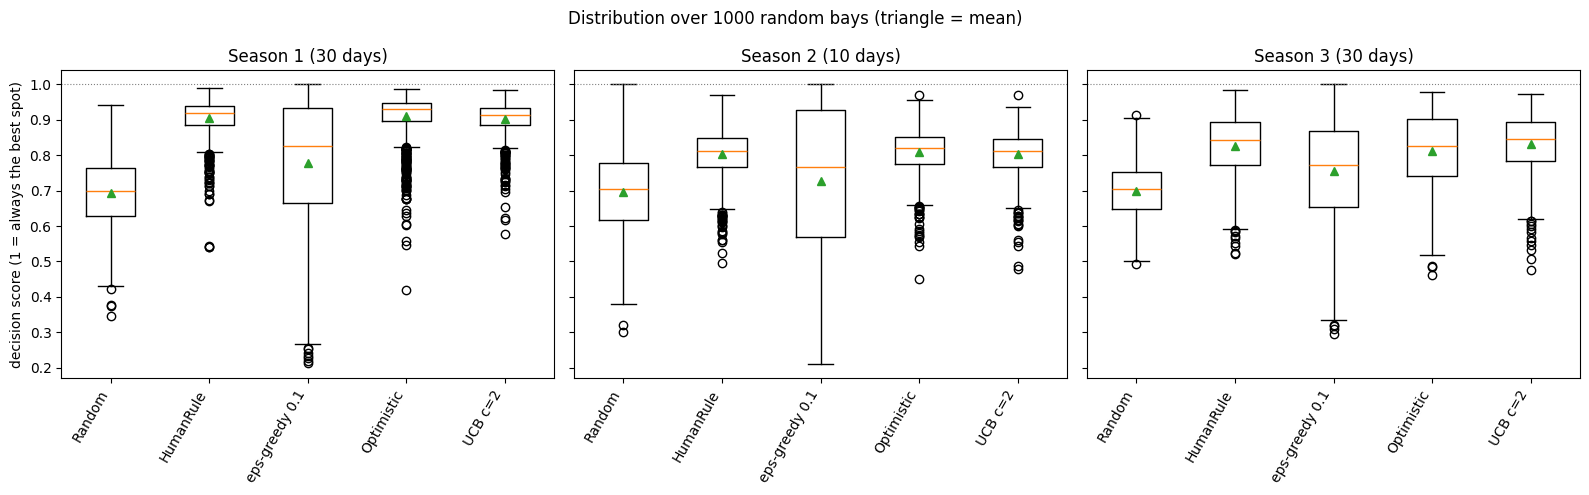

In [14]:
# Boxplots of the decision score: the whole distribution over the 1000 bays, per agent and season
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
for ax, s in zip(axes, SEASONS):
    ax.boxplot([RESULTS[name, s][2] for name in AGENTS], showmeans=True)
    ax.set_xticks(range(1, len(AGENTS) + 1), list(AGENTS), rotation=60, ha="right")
    ax.set_title(f"Season {s} ({BAYS[s][0].days} days)")
    ax.axhline(1.0, color="grey", lw=0.8, ls=":")
axes[0].set_ylabel("decision score (1 = always the best spot)")
fig.suptitle("Distribution over 1000 random bays (triangle = mean)")
plt.tight_layout(); plt.show()

**Observation.**
- **Season 1 (30 days):** Optimistic (0.909), HumanRule (0.905) and UCB (0.903) are equally good: all three try
  every spot early, then exploit.
- **Season 2 (10 days):** the same three stay within 0.01 of each other (about 0.80). Half the season is gone
  before the five spots have been tried, so there is little left to win.
- **Season 3 (change on day 16):** UCB is ahead (0.832); its bonus keeps re-testing the spots it has neglected.
- **eps-greedy is the weak one everywhere** (0.73 - 0.78), and by far the most spread out (sd 0.14 - 0.22):
  starting from Q = 0 it settles on the first spot that looks good and leaves it only by chance.

### 1.3 Task 3 (part b): does the decision score separate decisions from luck?

A measure that reflects decisions only should vary little for the same agent across bays, and should rank two
agents the same way on almost every bay. We check both, with `HumanRule` against `Random` on the same 1000 bays.

In [15]:
for s in SEASONS:
    tot_h, eff_h, dec_h = RESULTS["HumanRule", s]
    tot_r, eff_r, dec_r = RESULTS["Random", s]
    print(f"Season {s}: coefficient of variation (sd/mean) of HumanRule: "
          f"total {tot_h.std()/tot_h.mean():.3f}, efficiency {eff_h.std()/eff_h.mean():.3f}, "
          f"decision {dec_h.std()/dec_h.mean():.3f}")
    print(f"          HumanRule beats Random on the same bay: total {np.mean(tot_h > tot_r):.0%}, "
          f"efficiency {np.mean(eff_h > eff_r):.0%}, decision {np.mean(dec_h > dec_r):.0%}")

Season 1: coefficient of variation (sd/mean) of HumanRule: total 0.157, efficiency 0.081, decision 0.058
          HumanRule beats Random on the same bay: total 96%, efficiency 96%, decision 98%
Season 2: coefficient of variation (sd/mean) of HumanRule: total 0.191, efficiency 0.145, decision 0.086
          HumanRule beats Random on the same bay: total 75%, efficiency 75%, decision 87%
Season 3: coefficient of variation (sd/mean) of HumanRule: total 0.158, efficiency 0.125, decision 0.107
          HumanRule beats Random on the same bay: total 85%, efficiency 85%, decision 90%


**Observation.** For the same agent the total varies most across bays (coefficient of variation 0.16) and
the decision score least (0.06). And the better agent wins on more bays with the decision score than with the
total (87% against 75% in Season 2). The decision score is the measure we use everywhere.

## 2. Your team's bays

Run your agents on the bays played by your team members and compare with their results.
`FishingBay.from_log(log, season)` rebuilds the exact bay a member played, with the same catch on every day.

Agents are random (exploration, tie-breaking), so on each team bay we run every agent with
100 different agent seeds and report the mean, and the fraction of runs that beat the team member.
The bay (the catch of every spot on every day) is exactly the one the member played.

In [16]:
# =============================================================================
# Section 2 - our agents on the exact bays our team played
# =============================================================================
# Purpose: each member played one bay per season. FishingBay.from_log rebuilds
# that exact bay (same catch at every spot on every day), so we can ask: would an
# agent have caught more than the member did, on the very same bay?
#
# Our agents are random (exploration, tie-breaking), so one run proves nothing:
# we replay each agent 100 times on the same bay, with 100 different agent seeds.
#
# TEAM[agent, member, season] = array of the 100 total catches, in kg.
# The table reports, for each agent and each member's bay:
#   - the MEAN of those 100 totals, in kg;
#   - in brackets, the share of the 100 runs that caught MORE than the member did
#     in the real game (50% = as good as the member, 100% = better every time).
# The row "member (real game)" is the reference: the kg the member actually caught
# on that bay when they played it. It is not an agent.

N_RUNS = 100
TEAM = {}   # (agent, member, season) -> array of 100 total catches (kg)
for name, log in zip(NAMES, logs):
    for s in SEASONS:
        bay = FishingBay.from_log(log, season=s)       # exact bay this member played
        for agent_name, make in AGENTS.items():
            TEAM[agent_name, name, s] = np.array([play(make(r), bay) for r in range(N_RUNS)])

for s in SEASONS:
    print(f"\n=== Season {s} " + "=" * 62)
    print(f"    mean total catch (kg) over {N_RUNS} runs, and (share of runs that beat the member)")
    print(f"{'agent':20s}" + "".join(f"{n:>22s}" for n in NAMES))
    print(f"{'member (real game)':20s}" + "".join(f"{HUMAN[n, s][0]:>13.1f} kg        " for n in NAMES))
    for agent_name in AGENTS:
        cells = [f"{TEAM[agent_name, n, s].mean():6.1f} kg ({np.mean(TEAM[agent_name, n, s] > HUMAN[n, s][0]):4.0%})"
                 for n in NAMES]
        print(f"{agent_name:20s}" + "".join(f"{c:>22s}" for c in cells))


=== Season 1 ==============================================================
    mean total catch (kg) over 100 runs, and (share of runs that beat the member)
agent                              bouazza              kanakara               kumarsh
member (real game)          176.3 kg                198.6 kg                232.9 kg        
Random                     164.9 kg ( 21%)       218.6 kg ( 91%)       241.9 kg ( 74%)
HumanRule                  187.0 kg ( 68%)       266.7 kg (100%)       275.6 kg (100%)
eps-greedy 0.1             180.2 kg ( 66%)       241.1 kg ( 86%)       263.6 kg ( 89%)
Optimistic                 189.5 kg ( 69%)       266.0 kg (100%)       275.0 kg (100%)
UCB c=2                    192.7 kg ( 79%)       262.5 kg (100%)       273.1 kg (100%)

=== Season 2 ==============================================================
    mean total catch (kg) over 100 runs, and (share of runs that beat the member)
agent                              bouazza              kanakara   

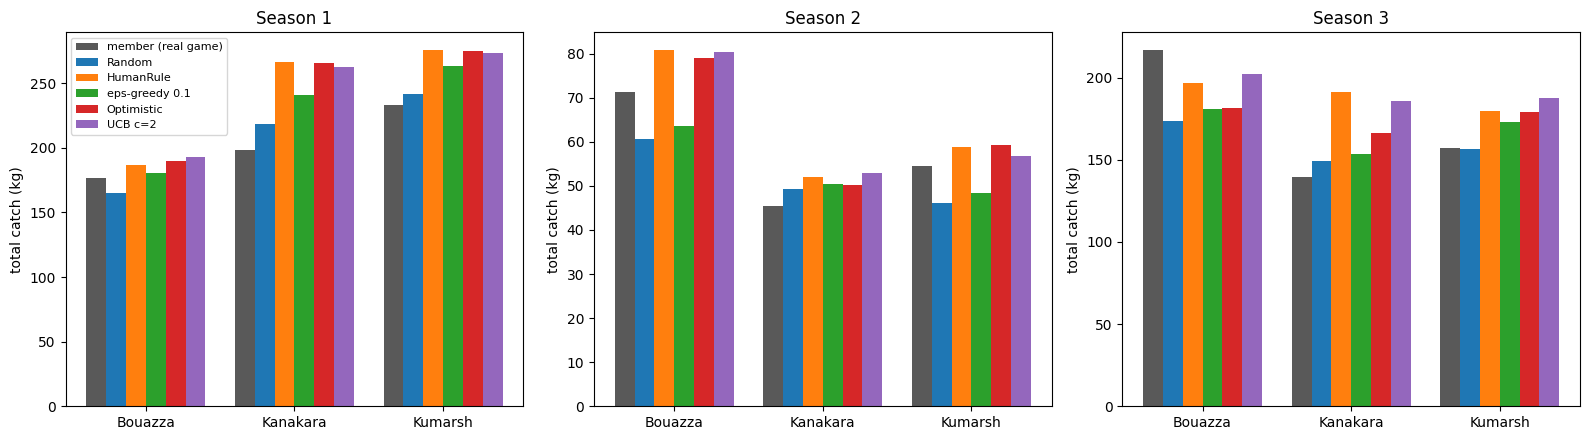

In [17]:
# Same comparison as a figure. Grey = what the member really caught on that bay,
# coloured = mean total catch of each agent over its 100 runs on that same bay.
show = list(AGENTS)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
x = np.arange(len(NAMES)); w = 0.8 / (len(show) + 1)
for ax, s in zip(axes, SEASONS):
    ax.bar(x, [HUMAN[n, s][0] for n in NAMES], w, label="member (real game)", color="0.35")
    for i, a in enumerate(show):
        ax.bar(x + (i + 1) * w, [TEAM[a, n, s].mean() for n in NAMES], w, label=a)
    ax.set_xticks(x + w * len(show) / 2, [n.capitalize() for n in NAMES])
    ax.set_title(f"Season {s}"); ax.set_ylabel("total catch (kg)")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Observation.** The three learning agents beat kanakara and kumarsh on **every** bay and season, and beat
bouazza in Seasons 1 and 2. **Season 3 on bouazza's bay is the only failure**: the best of them (HumanRule and
UCB) wins just 18% of the runs against his 216.7 kg. He kept re-testing spots he had not visited for a while,
which is what pays after the change. Random and eps-greedy are below the humans in several cases.

## 3. Seasons 2 and 3

Identify the best agent for Season 2 and for Season 3, and explain why.
`FishingBay(season, seed, days=..., shift_day=...)` lets you experiment with longer seasons.

**Ranking with paired comparisons.** All agents played the same 1000 bays, so we compare the best agent
with each other agent bay by bay (paired difference of decision scores). A 95% interval that does
not contain 0 means the difference is not due to chance.

In [18]:
for s in (2, 3):
    ranking = sorted(AGENTS, key=lambda a: -RESULTS[a, s][2].mean())
    best = ranking[0]
    print(f"\nSeason {s}: best agent = {best} (mean decision score {RESULTS[best, s][2].mean():.3f})")
    for other in ranking[1:]:
        d = RESULTS[best, s][2] - RESULTS[other, s][2]
        se = d.std(ddof=1) / np.sqrt(len(d))
        print(f"   vs {other:20s} difference {d.mean():+.3f}  95% CI [{d.mean()-1.96*se:+.3f}, {d.mean()+1.96*se:+.3f}]"
              f"  better on {np.mean(d > 0):.0%} of bays")


Season 2: best agent = Optimistic (mean decision score 0.810)
   vs HumanRule            difference +0.006  95% CI [+0.003, +0.010]  better on 41% of bays
   vs UCB c=2              difference +0.008  95% CI [+0.004, +0.011]  better on 46% of bays
   vs eps-greedy 0.1       difference +0.082  95% CI [+0.069, +0.095]  better on 59% of bays
   vs Random               difference +0.114  95% CI [+0.108, +0.120]  better on 88% of bays

Season 3: best agent = UCB c=2 (mean decision score 0.832)
   vs HumanRule            difference +0.006  95% CI [+0.001, +0.011]  better on 51% of bays
   vs Optimistic           difference +0.019  95% CI [+0.014, +0.025]  better on 49% of bays
   vs eps-greedy 0.1       difference +0.078  95% CI [+0.069, +0.087]  better on 64% of bays
   vs Random               difference +0.133  95% CI [+0.127, +0.138]  better on 92% of bays


**Best agents** (paired comparisons on the same 1000 bays).
- **Season 2: `Optimistic`** (0.810). Its lead is real but tiny: +0.006 over `HumanRule` and +0.008 over `UCB`
  (95% intervals exclude 0, but it is better on only ~45% of individual bays). With 10 days the best plan is
  simply to try each spot once and then exploit, which is what optimistic initial values do with no wasted day.
- **Season 3: `UCB`** (0.832), ahead of every other agent (+0.006 over `HumanRule`, +0.019 over `Optimistic`).
  Section 4 shows that a constant step size ($\alpha = 0.5$) raises UCB to **0.853**, our best Season 3 setting:
  after the change, forgetting the old catches is what matters.

**What happens day by day in Season 3?** We plot, for each day, the true average of the spot chosen
divided by the best true average of that day (1 = best spot), averaged over the 1000 bays.
The dotted line is the change of the fish populations (day 16).

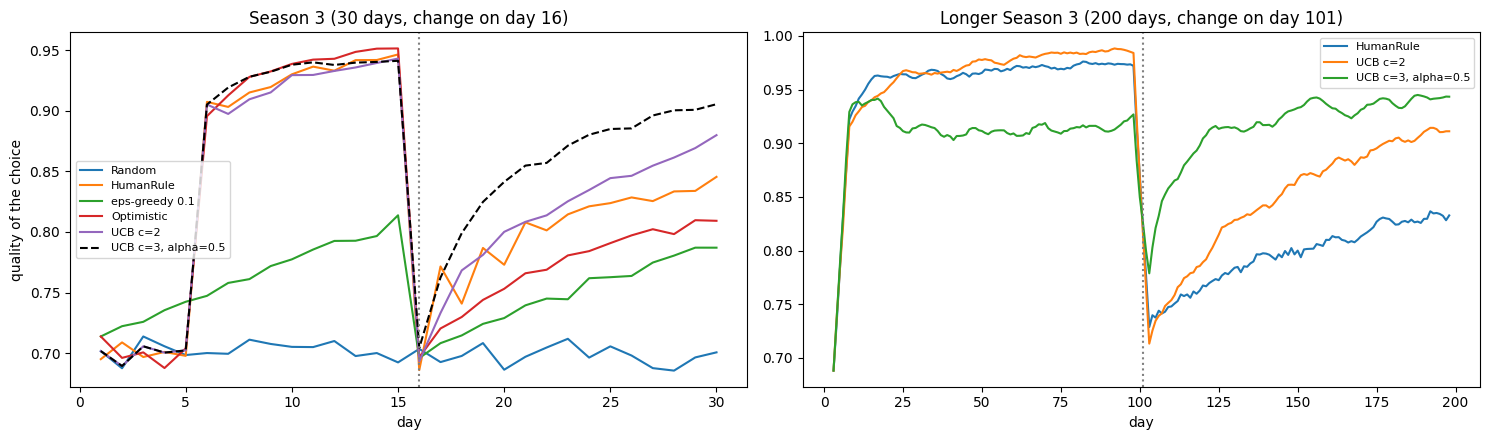

In [19]:
def daily_quality(make_agent, bays):
    """Per day: true mean of the chosen spot / best true mean of that day, averaged over bays."""
    q = np.zeros(bays[0].days)
    for bay in bays:
        play(make_agent(bay.seed), bay)
        for d, (spot, _) in enumerate(bay.history):
            r = bay.reveal()
            means = r["means_after_change"] if ("change_day" in r and d + 1 >= r["change_day"]) else r["means"]
            q[d] += means[spot] / max(means)
    return q / len(bays)

# UCB with a constant step size: same agent of section 1.2, two parameters changed (Sections 2.4 + 2.6)
UCB_ALPHA = lambda seed: UCBAgent(seed=seed, c=3.0, alpha=0.5)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for name in AGENTS:
    axes[0].plot(range(1, 31), daily_quality(AGENTS[name], BAYS[3]), label=name)
axes[0].plot(range(1, 31), daily_quality(UCB_ALPHA, BAYS[3]), "k--", label="UCB c=3, alpha=0.5")
axes[0].axvline(16, ls=":", color="grey"); axes[0].set_title("Season 3 (30 days, change on day 16)")
axes[0].set_xlabel("day"); axes[0].set_ylabel("quality of the choice"); axes[0].legend(fontsize=8)

# Longer season (allowed by the simulator): 200 days, change on day 101, 200 bays.
# With more time, the difference between forgetting and not forgetting is clear.
long_bays = [FishingBay(season=3, seed=seed, days=200, shift_day=101) for seed in range(200)]
for name, make in [("HumanRule", AGENTS["HumanRule"]), ("UCB c=2", AGENTS["UCB c=2"]),
                   ("UCB c=3, alpha=0.5", UCB_ALPHA)]:
    q = daily_quality(make, long_bays)
    axes[1].plot(range(3, 199), np.convolve(q, np.ones(5) / 5, mode="valid"), label=name)  # 5-day average
axes[1].axvline(101, ls=":", color="grey"); axes[1].set_title("Longer Season 3 (200 days, change on day 101)")
axes[1].set_xlabel("day"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Observation.** On day 16 every agent falls back to the random level. UCB with a constant step size (dashed)
recovers fastest: 0.90 by day 30, against 0.88 for UCB, 0.85 for HumanRule and 0.81 for Optimistic. Old catches
lose weight geometrically (eq. 2.6), while sample averages still carry 15 days of obsolete data. The 200-day plot
shows the price: before the change, forgetting costs about 0.06; after it, the forgetting agent is back above 0.9
within ~25 days, while the others are still below their old level 100 days later.

## 4. One parameter

Study the effect of one parameter of one method.

We study the exploration parameter **c of UCB** (eq. 2.8), from 0 (pure greedy after trying each
spot once) to 12 (almost uniform exploration), for each season, with sample averages (alpha = None)
and with a constant step size (alpha = 0.5). Mean decision score over the same 1000 bays, with
95% intervals.

Season 1, alpha=None: best c = 0.5 (score 0.911); c=0: 0.910, c=0.5: 0.911, c=1: 0.910, c=2: 0.903, c=3: 0.890, c=4: 0.874, c=6: 0.841, c=8: 0.814, c=12: 0.780
Season 1, alpha=0.5: best c = 1 (score 0.905); c=0: 0.898, c=0.5: 0.904, c=1: 0.905, c=2: 0.901, c=3: 0.889, c=4: 0.869, c=6: 0.830, c=8: 0.806, c=12: 0.776
Season 2, alpha=None: best c = 0 (score 0.809); c=0: 0.809, c=0.5: 0.808, c=1: 0.807, c=2: 0.802, c=3: 0.798, c=4: 0.792, c=6: 0.778, c=8: 0.763, c=12: 0.742
Season 2, alpha=0.5: best c = 2 (score 0.810); c=0: 0.808, c=0.5: 0.809, c=1: 0.810, c=2: 0.810, c=3: 0.809, c=4: 0.807, c=6: 0.795, c=8: 0.775, c=12: 0.736
Season 3, alpha=None: best c = 3 (score 0.836); c=0: 0.818, c=0.5: 0.822, c=1: 0.827, c=2: 0.832, c=3: 0.836, c=4: 0.830, c=6: 0.815, c=8: 0.796, c=12: 0.768
Season 3, alpha=0.5: best c = 3 (score 0.853); c=0: 0.825, c=0.5: 0.833, c=1: 0.839, c=2: 0.851, c=3: 0.853, c=4: 0.849, c=6: 0.832, c=8: 0.810, c=12: 0.785


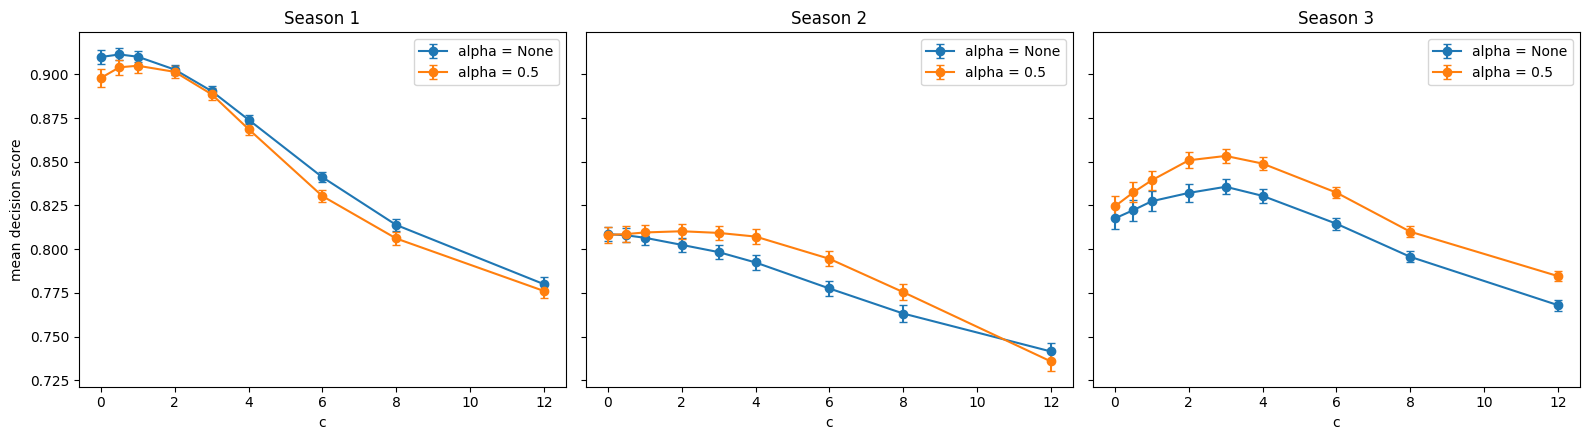

In [20]:
C_VALUES = [0, 0.5, 1, 2, 3, 4, 6, 8, 12]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, s in zip(axes, SEASONS):
    for alpha in (None, 0.5):
        means, ci = [], []
        for c in C_VALUES:
            dec = evaluate(lambda seed: UCBAgent(seed=seed, c=c, alpha=alpha), s)[2]
            means.append(dec.mean()); ci.append(1.96 * dec.std(ddof=1) / np.sqrt(len(dec)))
        ax.errorbar(C_VALUES, means, yerr=ci, marker="o", capsize=3, label=f"alpha = {alpha}")
        best = int(np.argmax(means))
        print(f"Season {s}, alpha={alpha}: best c = {C_VALUES[best]} (score {means[best]:.3f}); "
              + ", ".join(f"c={c}: {m:.3f}" for c, m in zip(C_VALUES, means)))
    ax.set_title(f"Season {s}"); ax.set_xlabel("c"); ax.legend()
axes[0].set_ylabel("mean decision score")
plt.tight_layout(); plt.show()

**Observation.** The best `c` depends on the season: about 0 - 1 in Season 1, **0 in Season 2** (every
exploration day is expensive when there are only 10), and **3 in Season 3**, where the agent has to explore again
to notice the change. Too much exploration (c = 12) brings every season back to random play. The constant step
size ($\alpha = 0.5$, orange) helps only in Season 3 and costs a little in the two stationary seasons.

## 5. Part IV (optional): contextual bay

`ContextualBay(seed)` lasts 300 days. Each morning, your agent receives the conditions
`x = [wind_kmh, waves_m, tide_m]` before choosing a spot. Contextual agents are subclasses of
`ContextualAgent` in `agents.py`.

In [21]:
bay = ContextualBay(seed=0)
total = play(RandomContextualAgent(seed=0), bay)
print(f"Random contextual agent: {total} kg over {bay.days} days")

# Your code here

Random contextual agent: 1945.7 kg over 300 days


### 5.1 Which predictor: linear regression or KNN?

Task 6 asks for **one** of the two, so we choose on evidence, as we did for the human rules in 1.1.
We read `fishing.py` first: `ContextualBay` builds the true mean catch as `clip(base + z @ weights.T, 0, None)`,
where `z` are the conditions scaled to [0, 1]. The mean catch is therefore a **linear** function of the conditions.
We then give both predictors the same training days and compare how well they predict the true mean catch on
days they have not seen.

In [22]:
# Prediction accuracy of the two models on the SAME data, on two bays.
# We play one season to collect the conditions of the 300 days (bay.history) and
# take the true mean catches from bay.reveal(). Both models are then trained on the
# same 150 days (all five spots, with the game's noise) and tested on the other 150.
rng = np.random.default_rng(0)
print("mean absolute error on the true mean catch of a spot, in kg (lower is better)")
print(f"{'bay seed':>9s} {'linear regression':>20s} {'KNN (k=10)':>14s}")
for seed in (0, 61):
    bay = ContextualBay(seed=seed)
    play(RandomContextualAgent(seed=0), bay)                 # walk the season to get the conditions
    X = np.array([list(cond.values()) for cond, _, _ in bay.history])
    true = bay.reveal()                                      # 300 days x 5 spots of true means
    days = rng.permutation(bay.days); train, test = days[:150], days[150:]
    noise = rng.normal(0.0, 2.5, true.shape)                 # same catch noise as the game
    lin, knn = LinearRegressionAgent(seed=0), KNNAgent(seed=0, k=10)
    lin.reset(); knn.reset()
    for d in train:                                          # exactly the same training data for both
        for spot in range(len(SPOTS)):
            y = max(true[d, spot] + noise[d, spot], 0.0)
            lin.update(X[d], spot, y)
            knn.update(X[d], spot, y)
    err_lin = np.mean([np.abs(lin.predict(X[d]) - true[d]).mean() for d in test])
    err_knn = np.mean([np.abs(knn.predict(X[d]) - true[d]).mean() for d in test])
    print(f"{seed:9d} {err_lin:20.2f} {err_knn:14.2f}")

mean absolute error on the true mean catch of a spot, in kg (lower is better)
 bay seed    linear regression     KNN (k=10)
        0                 0.47           0.74
       61                 0.52           0.79


**Choice: linear regression.** It is the model the simulator actually uses, and on the same data it predicts
the mean catch with **about 35% less error** than KNN (0.47 and 0.52 kg against 0.74 and 0.79 kg). It also needs
far less data (4 numbers per spot instead of a whole history) and extends directly to the fix in 5.3.
**From here on we use linear regression only**; `KNNAgent` stays in `agents.py` for this comparison.

### 5.2 Comparison on 200 contextual bays, against the best agent of Part III

Contextual bays last 300 days, so we use 200 bays (seeds 0 to 199). We compare the best agent of Part III,
`UCB`, which ignores the conditions (wrapped by `ContextualWrapper`, since `play()` refuses an `Agent` on a
`ContextualBay`); the regression agent acting **only on its predictions**; and two ways of keeping it exploring.
Measure: `total / best_possible`, where `best_possible` fishes the best spot **for each day's conditions**.

agent                        mean     sd  worst bay     5%  median
UCB c=2 (Part III)          0.935  0.062      0.711  0.796   0.956
LinReg, predictions only    0.929  0.081      0.597  0.737   0.957
LinReg + eps-greedy 0.05    0.928  0.056      0.655  0.831   0.945
LinUCB c=5                  0.964  0.033      0.787  0.895   0.972
Random                      0.585  0.086      0.349  0.449   0.589


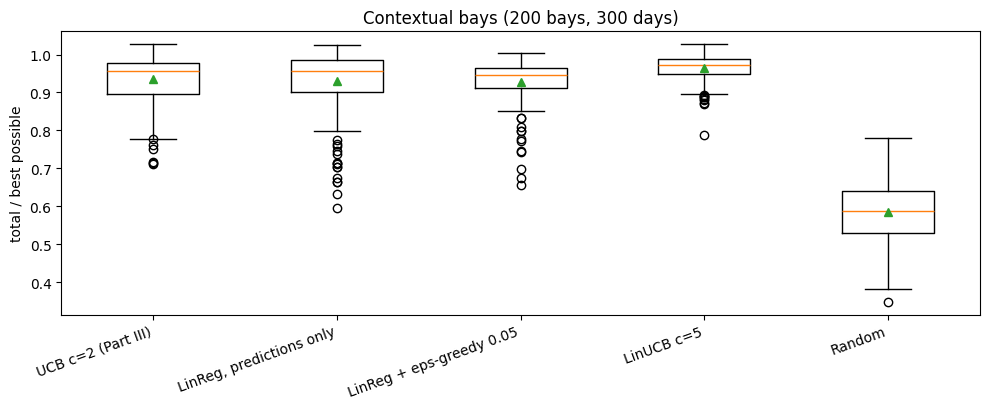

In [23]:
CBAYS = [ContextualBay(seed=seed) for seed in range(200)]
CAGENTS = {
    # the best agent of Part III, which never looks at the conditions
    "UCB c=2 (Part III)":       lambda seed: ContextualWrapper(UCBAgent(seed=seed, c=2.0)),
    # linear regression per spot, choosing the spot with the best predicted catch
    "LinReg, predictions only": lambda seed: LinearRegressionAgent(seed=seed, warmup=1, epsilon=0.0),
    "LinReg + eps-greedy 0.05": lambda seed: LinearRegressionAgent(seed=seed, warmup=1, epsilon=0.05),
    "LinUCB c=5":               lambda seed: LinUCBAgent(seed=seed, c=5.0),
    "Random":                   lambda seed: RandomContextualAgent(seed=seed),
}
CRES = {name: np.array([play(make(b.seed), b) / b.best_possible() for b in CBAYS])
        for name, make in CAGENTS.items()}

print(f"{'agent':26s} {'mean':>6s} {'sd':>6s} {'worst bay':>10s} {'5%':>6s} {'median':>7s}")
for name, r in CRES.items():
    print(f"{name:26s} {r.mean():6.3f} {r.std():6.3f} {r.min():10.3f} {np.percentile(r, 5):6.3f} {np.median(r):7.3f}")

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.boxplot(list(CRES.values()), showmeans=True)
ax.set_xticks(range(1, len(CRES) + 1), list(CRES), rotation=20, ha="right")
ax.set_ylabel("total / best possible"); ax.set_title("Contextual bays (200 bays, 300 days)")
plt.tight_layout(); plt.show()

**Observation.**
- **LinUCB is the best** (mean 0.964) and the most robust (worst bay 0.787).
- **Acting only on the predictions is fragile**: good median (0.957) but a bad tail (worst bay 0.597).
- **The best agent of Part III reaches 0.935 without ever looking at the conditions.** In most bays one spot is
  best on almost every day, so the conditions only decide the remaining days - and that is where the 3 points
  between 0.935 and 0.964 come from.

### 5.3 A case where acting only on the predictions fails, and the fix

We take the bay where the "predictions only" agent does worst, and look at what it did: how many days it fished
each spot, its final prediction for each spot (at average conditions), and the truth. Then LinUCB on the same bay.

In [24]:
worst = int(np.argmin(CRES["LinReg, predictions only"]))
bay = CBAYS[worst]
print(f"Worst bay for 'predictions only': seed {bay.seed}, "
      f"score {CRES['LinReg, predictions only'][worst]:.3f} (LinUCB on this bay: {CRES['LinUCB c=5'][worst]:.3f})\n")

x_avg = np.array([20.0, 1.5, 1.0])                                  # average conditions
true_mean = bay.reveal()                                             # days x 5 true averages
best_share = np.bincount(true_mean.argmax(axis=1), minlength=5) / bay.days

for label, agent in [("predictions only", LinearRegressionAgent(seed=bay.seed, warmup=1, epsilon=0.0)),
                     ("LinUCB c=5", LinUCBAgent(seed=bay.seed, c=5.0))]:
    play(agent, bay)
    visits = np.bincount([s for _, s, _ in bay.history], minlength=5)
    first5 = [(SPOTS[s], c) for _, s, c in bay.history[:5]]
    print(f"--- {label} ---")
    if label == "predictions only":
        print("warm-up catches (one per spot):", first5)
    pred = agent.predict(x_avg)
    for k in range(5):
        print(f"  {SPOTS[k]:16s} days fished {visits[k]:4d} | predicted {pred[k]:5.1f} kg | "
              f"true mean over season {true_mean[:, k].mean():5.1f} kg | best spot on {best_share[k]:4.0%} of days")

Worst bay for 'predictions only': seed 61, score 0.597 (LinUCB on this bay: 0.965)

--- predictions only ---
warm-up catches (one per spot): [('Seagrass Bed', 13.8), ('Rocky Point', 9.2), ('Lighthouse Reef', 3.2), ('Deep Channel', 0.0), ('Old Pier', 6.0)]
  Old Pier         days fished    1 | predicted   3.7 kg | true mean over season  13.7 kg | best spot on  99% of days
  Rocky Point      days fished    1 | predicted   5.2 kg | true mean over season   7.3 kg | best spot on   0% of days
  Seagrass Bed     days fished  296 | predicted   8.1 kg | true mean over season   8.4 kg | best spot on   0% of days
  Deep Channel     days fished    1 | predicted   0.0 kg | true mean over season   2.3 kg | best spot on   0% of days
  Lighthouse Reef  days fished    1 | predicted   1.9 kg | true mean over season   1.8 kg | best spot on   0% of days
--- LinUCB c=5 ---
  Old Pier         days fished  270 | predicted  13.7 kg | true mean over season  13.7 kg | best spot on  99% of days
  Rocky Point    

**Why it fails.** After the warm-up, the agent fishes a spot only if its prediction is the highest. A spot that
gave one unlucky catch (noise sd = 2.5 kg) gets a low prediction and is **never fished again**, so that prediction
is never corrected: the mistake confirms itself. It is the exploration problem of Part III, now per condition.

**The fix: keep exploring.** Two versions, both in `agents.py`:
- *epsilon-greedy on the predictions* (Section 2.2): a random spot 5% of the days. It repairs the worst cases
  (5% quantile 0.74 -> 0.83) but explores blindly forever, so the mean does not improve.
- **LinUCB** (Section 2.6 applied per context): add to each prediction a bonus `c * sqrt(phi^T A^-1 phi)`, the
  uncertainty of *today's* prediction. Exploration goes where the model is unsure, and stops where it is sure.
  It is the best agent of 5.2 (0.964) and it turns this bay from 0.60 into 0.96.